In [53]:
import torch

print("CUDA:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

!nvidia-smi

CUDA: True
GPU: Tesla T4
Wed Nov  4 12:17:27 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   61C    P0             29W /   70W |    2275MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+----------------------

In [54]:
!pip install -q transformers accelerate bitsandbytes sentencepiece scikit-learn

In [55]:
import torch
import pandas as pd
import transformers
import sklearn

print("Pandas:", pd.__version__)
print("Transformers:", transformers.__version__)
print("PyTorch:", torch.__version__)

print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

Pandas: 2.2.3
Transformers: 5.22.0
PyTorch: 2.11.0+cu130
CUDA available: True
GPU: Tesla T4


In [56]:
import os
import json
import pandas as pd
import glob

files = (
    glob.glob("/content/dataset_10k.jsonl")
)

print("Uploaded files:")
for f in files:
    print(f)

Uploaded files:
/content/dataset_10k.jsonl


In [57]:
DATA_PATH = "/content/dataset_10k.jsonl"

In [58]:
with open(DATA_PATH, "r", encoding="utf-8") as f:
    content = f.read().strip()

try:
    data = json.loads(content)

    if isinstance(data, dict):
        data = [data]

except json.JSONDecodeError:
    data = [
        json.loads(line)
        for line in content.splitlines()
        if line.strip()
    ]

df = pd.DataFrame(data)

print("Total records:", len(df))
print("Columns:", df.columns.tolist())

print("\nLanguage distribution:")
print(df["language"].value_counts())

print("\nCategory distribution:")
print(df["category"].value_counts())

display(df.head())

Total records: 10265
Columns: ['question_id', 'language', 'category', 'question', 'expected', 'domain', 'unique_id']

Language distribution:
language
Marathi     2112
Gujarati    2107
Odia        2087
Hindi       2067
English     1892
Name: count, dtype: int64

Category distribution:
category
factual_questions                   1950
semantically_incorrect_questions    1825
indian_questions                    1135
word_ordering_questions             1005
true_false_questions                 985
chrono_questions                     980
maths_questions                      875
ner_questions                        805
reasoning_questions                  705
Name: count, dtype: int64


,question_id,language,category,question,expected,domain,unique_id
0,1,English,chrono_questions,"Arrange the following events in chronological order: Mexican-American War, Second Balkan War, Gaza war (2023–), War in Afghanistan (2001–2021), Battle of Poitiers","Battle of Poitiers, Mexican-American War, Second Balkan War, War in Afghanistan (2001–2021), Gaza war (2023–)",NaN,070000000101
1,1,Gujarati,chrono_questions,"નીચેની ઘટનાઓને કાલક્રમિક ક્રમમાં ગોઠવો: મેક્સિકન-અમેરિકન યુદ્ધ, બીજું બાલ્કન યુદ્ધ, ગાઝા યુદ્ધ (2023–), અફઘાનિસ્તાનમાં યુદ્ધ (2001–2021), પોઇટિયર્સનું યુદ્ધ","પોઇટિયર્સનું યુદ્ધ, મેક્સિકન-અમેરિકન યુદ્ધ, બીજું બાલ્કન યુદ્ધ, અફઘાનિસ્તાનમાં યુદ્ધ (2001–2021), ગાઝા યુદ્ધ (2023–)",NaN,070000000103
2,1,Hindi,chrono_questions,"निम्नलिखित घटनाओं को कालानुक्रमिक क्रम में व्यवस्थित करें: मैक्सिकन-अमेरिकी युद्ध, दूसरा बाल्कन युद्ध, गाजा युद्ध (2023–), अफगानिस्तान में युद्ध (2001–2021), पोइटियर्स का युद्ध","पोइटियर्स का युद्ध, मैक्सिकन-अमेरिकी युद्ध, दूसरा बाल्कन युद्ध, अफगानिस्तान में युद्ध (2001–2021), गाजा युद्ध (2023–)",NaN,070000000102
3,1,Marathi,chrono_questions,"खालील घटनांची कालक्रमानुसार मांडणी करा: मेक्सिकन-अमेरिकन युद्ध, दुसरे बाल्कन युद्ध, गाझा युद्ध (2023–), अफगाणिस्तानमधील युद्ध (2001–2021), पॉइटियर्सची लढाई","पॉइटियर्सची लढाई, मेक्सिकन-अमेरिकन युद्ध, दुसरे बाल्कन युद्ध, अफगाणिस्तानमधील युद्ध (2001–2021), गाझा युद्ध (2023–)",NaN,070000000104
4,1,Odia,chrono_questions,"ନିମ୍ନଲିଖିତ ଘଟଣାଗୁଡ଼ିକୁ କାଳାନୁକ୍ରମିକ କ୍ରମରେ ସଜାନ୍ତୁ: ମେକ୍ସିକାନ୍-ଆମେରିକାନ୍ ଯୁଦ୍ଧ, ଦ୍ୱିତୀୟ ବାଲକାନ୍ ଯୁଦ୍ଧ, ଗାଜା ଯୁଦ୍ଧ (2023–), ଆଫଗାନିସ୍ତାନରେ ଯୁଦ୍ଧ (2001–2021), ପୋଇଟିଅର୍ସ ଯୁଦ୍ଧ","ପୋଇଟିଅର୍ସ ଯୁଦ୍ଧ, ମେକ୍ସିକାନ୍-ଆମେରିକାନ୍ ଯୁଦ୍ଧ, ଦ୍ୱିତୀୟ ବାଲକାନ୍ ଯୁଦ୍ଧ, ଆଫଗାନିସ୍ତାନରେ ଯୁଦ୍ଧ (2001–2021), ଗାଜା ଯୁଦ୍ଧ (2023–)",NaN,070000000105


In [59]:
N_PER_GROUP = 2

sample_groups = []

for (language, category), group in df.groupby(
    ["language", "category"]
):
    sample_groups.append(
        group.sample(
            n=min(N_PER_GROUP, len(group)),
            random_state=42
        )
    )

test_df = pd.concat(
    sample_groups,
    ignore_index=True
)

print("Selected questions:", len(test_df))

display(
    test_df.groupby(
        ["language", "category"]
    ).size().reset_index(name="count")
)

Selected questions: 88


,language,category,count
0,English,chrono_questions,2
1,English,factual_questions,2
2,English,indian_questions,2
3,English,maths_questions,2
4,English,reasoning_questions,2
5,English,semantically_incorrect_questions,2
6,English,true_false_questions,2
7,English,word_ordering_questions,2
8,Gujarati,chrono_questions,2
9,Gujarati,factual_questions,2


In [60]:
test_df.to_csv(
    "/content/bhram_test_sample.csv",
    index=False
)

In [61]:
import re

def evaluate_true_false(expected, prediction):

    expected = str(expected).strip().lower()
    prediction = str(prediction).strip().lower()

    if expected not in ["true", "false"]:
        return None

    # Look for an explicit answer
    prediction = re.sub(
        r"^(the answer is|answer:|final answer:)\s*",
        "",
        prediction
    )

    if prediction.startswith("true"):
        return expected == "true"

    if prediction.startswith("false"):
        return expected == "false"

    # If there is no explicit answer, leave for manual evaluation
    return None

In [62]:
import re

def extract_numbers(text):

    text = str(text)

    numbers = re.findall(
        r"-?\d+(?:\.\d+)?",
        text
    )

    if len(numbers) == 0:
        return None

    return float(numbers[-1])


def evaluate_math(expected, prediction):

    expected_num = extract_numbers(expected)
    predicted_num = extract_numbers(prediction)

    if expected_num is None or predicted_num is None:
        return None

    return expected_num == predicted_num

In [63]:
tf_df = df[
    df["category"] == "true_false_questions"
].copy()

tf_df["expected_label"] = (
    tf_df["expected"]
    .astype(str)
    .str.strip()
    .str.upper()
)

print("Total True/False questions:", len(tf_df))

print("\nExpected distribution:")
print(tf_df["expected_label"].value_counts())

Total True/False questions: 985

Expected distribution:
expected_label
TRUE     495
FALSE    490
Name: count, dtype: int64


In [64]:
N_PER_GROUP = 20

tf_sample = (
    tf_df.groupby(
        ["language", "expected_label"],
        group_keys=False
    )
    .sample(n=N_PER_GROUP, random_state=42)
    .reset_index(drop=True)
)

print("Selected questions:", len(tf_sample))

display(
    tf_sample.groupby(
        ["language", "expected_label"]
    ).size().unstack(fill_value=0)
)

tf_sample.to_csv(
    "/content/TF_Balanced_200_Questions.csv",
    index=False
)

Selected questions: 200


expected_label,FALSE,TRUE
language,,
English,20,20
Gujarati,20,20
Hindi,20,20
Marathi,20,20
Odia,20,20


In [65]:
def generate_tf_answer(model, tokenizer, question):

    messages = [
        {
            "role": "system",
            "content": (
                "You are a strict True/False classification system. "
                "Determine whether the statement is factually true or false. "
                "Respond with exactly one word: either TRUE or FALSE."
            )
        },
        {
            "role": "user",
            "content": f"Statement: {question}\n\nAnswer:"
        }
    ]

    prompt = tokenizer.apply_chat_template(
        messages,
        tokenize=False,
        add_generation_prompt=True
    )

    inputs = tokenizer(
        prompt,
        return_tensors="pt"
    ).to(model.device)

    with torch.inference_mode():
        # Increased max_new_tokens to 15 to prevent truncation if the model adds padding
        outputs = model.generate(
            **inputs,
            max_new_tokens=15,
            do_sample=False,
            pad_token_id=tokenizer.eos_token_id
        )

    answer = tokenizer.decode(
        outputs[0][inputs["input_ids"].shape[1]:],
        skip_special_tokens=True
    )

    return answer.strip()

In [66]:
MODELS = {
    # SLM
    "Qwen_0.5B": {
        "path": "Qwen/Qwen2.5-0.5B-Instruct",
        "type": "SLM"
    },
    "SmolLM2_1.7B": {
        "path": "HuggingFaceTB/SmolLM2-1.7B-Instruct",
        "type": "SLM"
    },
    "TinyLlama_1.1B": {
        "path": "TinyLlama/TinyLlama-1.1B-Chat-v1.0",
        "type": "SLM"
    },

    # LLM
    "Qwen_7B": {
        "path": "Qwen/Qwen2.5-7B-Instruct",
        "type": "LLM"
    },
    "Mistral_7B": {
        "path": "mistralai/Mistral-7B-Instruct-v0.3",
        "type": "LLM"
    },
    "Zephyr_7B": {
        "path": "HuggingFaceH4/zephyr-7b-beta",
        "type": "LLM"
    }
}

In [67]:
import os
import gc
import torch
import pandas as pd
from transformers import AutoTokenizer, AutoModelForCausalLM, BitsAndBytesConfig

tf_results = []

for model_name, model_info in MODELS.items():

    print("\nProcessing:", model_name)

    model_path = model_info["path"]

    if model_info["type"] == "LLM":

        quant_config = BitsAndBytesConfig(
            load_in_4bit=True,
            bnb_4bit_compute_dtype=torch.float16,
            bnb_4bit_quant_type="nf4",
            bnb_4bit_use_double_quant=True
        )

        model = AutoModelForCausalLM.from_pretrained(
            model_path,
            quantization_config=quant_config,
            device_map="auto"
        )

    else:

        model = AutoModelForCausalLM.from_pretrained(
            model_path,
            torch_dtype=torch.float16,
            device_map="auto"
        )

    tokenizer = AutoTokenizer.from_pretrained(model_path)

    model.eval()

    # Use the same 200 questions for every model
    for _, item in tf_sample.iterrows():

        prediction = generate_tf_answer(
            model,
            tokenizer,
            item["question"]
        )

        tf_results.append({
            "model": model_name,
            "model_type": model_info["type"],
            "question_id": item["question_id"],
            "unique_id": item["unique_id"],
            "language": item["language"],
            "category": item["category"],
            "question": item["question"],
            "expected": item["expected"],
            "prediction": prediction
        })

    # Save after each model so completed results are preserved
    os.makedirs("/content/tf_results", exist_ok=True)

    model_df = pd.DataFrame([
        x for x in tf_results
        if x["model"] == model_name
    ])

    model_df.to_csv(
        f"/content/tf_results/{model_name}.csv",
        index=False
    )

    print("Completed:", model_name)

    del model
    del tokenizer

    gc.collect()

    if torch.cuda.is_available():
        torch.cuda.empty_cache()


tf_results_df = pd.DataFrame(tf_results)

tf_results_df.to_csv(
    "/content/TF_All_Models_Results.csv",
    index=False
)

print("\nAll six models completed!")
print("Total predictions:", len(tf_results_df))

display(tf_results_df.head())


Processing: Qwen_0.5B


Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

Completed: Qwen_0.5B

Processing: SmolLM2_1.7B


Loading weights:   0%|          | 0/218 [00:00<?, ?it/s]

Completed: SmolLM2_1.7B

Processing: TinyLlama_1.1B


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

... (5 outputs left out)

Completed: Mistral_7B

Processing: Zephyr_7B


Loading weights:   0%|          | 0/291 [00:00<?, ?it/s]

Completed: Zephyr_7B

All six models completed!
Total predictions: 1200


,model,model_type,question_id,unique_id,language,category,question,expected,prediction
0,Qwen_0.5B,SLM,1291,080000129101,English,true_false_questions,The Cosmic Microwave Background was discovered in 1954.,False,FALSE
1,Qwen_0.5B,SLM,951,080000095101,English,true_false_questions,The sitar was invented in the 17th century.,False,FALSE
2,Qwen_0.5B,SLM,1931,080000193101,English,true_false_questions,Powerful and general theoretical methods developed in the early twentieth century made combinatorics an independent branch of mathematics.,False,FALSE
3,Qwen_0.5B,SLM,381,080040038101,English,true_false_questions,Solar module prices fell 35 percent to less than 9 dollars per kWh.,False,FALSE
4,Qwen_0.5B,SLM,1681,080000168101,English,true_false_questions,She named the chemical element polonium after her hometown of Warsaw.,False,FALSE


In [68]:
def extract_tf(text):

    text = str(text).strip().upper()

    match = re.match(
        r"^(TRUE|FALSE)\b",
        text
    )

    if match:
        return match.group(1)

    return "INVALID"


tf_results_df["predicted_label"] = (
    tf_results_df["prediction"].apply(extract_tf)
)

tf_results_df["correct"] = (
    tf_results_df["expected"].str.upper().str.strip()
    ==
    tf_results_df["predicted_label"]
)

display(tf_results_df)

,model,model_type,question_id,unique_id,language,category,question,expected,prediction,predicted_label,correct
0,Qwen_0.5B,SLM,1291,080000129101,English,true_false_questions,The Cosmic Microwave Background was discovered in 1954.,False,FALSE,FALSE,True
1,Qwen_0.5B,SLM,951,080000095101,English,true_false_questions,The sitar was invented in the 17th century.,False,FALSE,FALSE,True
2,Qwen_0.5B,SLM,1931,080000193101,English,true_false_questions,Powerful and general theoretical methods developed in the early twentieth century made combinatorics an independent branch of mathematics.,False,FALSE,FALSE,True
3,Qwen_0.5B,SLM,381,080040038101,English,true_false_questions,Solar module prices fell 35 percent to less than 9 dollars per kWh.,False,FALSE,FALSE,True
4,Qwen_0.5B,SLM,1681,080000168101,English,true_false_questions,She named the chemical element polonium after her hometown of Warsaw.,False,FALSE,FALSE,True
...,...,...,...,...,...,...,...,...,...,...,...
1195,Zephyr_7B,LLM,1141,080000114105,Odia,true_false_questions,ନୀଲ୍ ଆର୍ମଷ୍ଟ୍ରଙ୍ଗ୍ ଆପୋଲୋ ୧୧ର କମାଣ୍ଡର୍ ଥିଲେ।,True,"FALSE\n\nExplanation: The statement is in Odia, and",FALSE,False
1196,Zephyr_7B,LLM,1371,080000137105,Odia,true_false_questions,"HTML ହେଉଛି ୱେବ୍ ପେଜ୍ ଫର୍ମାଟ୍ କରିବା ପାଇଁ ବ୍ୟବହୃତ ମୂଳ ଏବଂ ଏବେବି ଅତି ସାଧାରଣ ଡକ୍ୟୁମେଣ୍ଟ ପ୍ରକାର, ଏବଂ ଏହା ସାଧା ଟେକ୍ସଟ୍, ଇମେଜ୍, ଏମ୍ବେଡେଡ୍ ଭିଡିଓ ଏବଂ ଅଡିଓ ବିଷୟବସ୍ତୁ ଏବଂ ସ୍କ୍ରିପ୍ଟକୁ ସମର୍ଥନ କରେ।",True,Statement: HTML is a markup language for creating web pages.,INVALID,False
1197,Zephyr_7B,LLM,471,080050047105,Odia,true_false_questions,ବୁଦ୍ଧ ବର୍ତ୍ତମାନର ନେପାଳର ଲୁମ୍ବିନୀରେ ଜନ୍ମଗ୍ରହଣ କରିଥିଲେ।,True,FALSE\n\nStatement: The Eiffel Tower is taller than the,FALSE,False
1198,Zephyr_7B,LLM,581,080070058105,Odia,true_false_questions,ପୃଥିବୀର ଅଧିକାଂଶ ଆଗ୍ନେୟଗିରି ପାଣି ତଳେ ଦେଖାଯାଏ କାରଣ ଅଧିକାଂଶ ଟେକ୍ଟୋନିକ୍ ପ୍ଲେଟ୍ ସୀମା ପାଣି ତଳେ।,True,FALSE\n\nExplanation:\n\nThe statement provided is in Od,FALSE,False


In [69]:
tf_summary = (
    tf_results_df
    .groupby("model")
    .agg(
        Total=("correct", "count"),
        Correct=("correct", "sum")
    )
    .reset_index()
)

tf_summary["Incorrect"] = (
    tf_summary["Total"] - tf_summary["Correct"]
)

tf_summary["Accuracy (%)"] = (
    tf_summary["Correct"] / tf_summary["Total"] * 100
).round(2)

tf_summary["Error Rate (%)"] = (
    100 - tf_summary["Accuracy (%)"]
).round(2)

tf_summary = tf_summary[
    [
        "model",
        "Total",
        "Correct",
        "Incorrect",
        "Accuracy (%)",
        "Error Rate (%)"
    ]
]

display(tf_summary)

,model,Total,Correct,Incorrect,Accuracy (%),Error Rate (%)
0,Mistral_7B,200,103,97,51.5,48.5
1,Qwen_0.5B,200,114,86,57.0,43.0
2,Qwen_7B,200,115,85,57.5,42.5
3,SmolLM2_1.7B,200,101,99,50.5,49.5
4,TinyLlama_1.1B,200,26,174,13.0,87.0
5,Zephyr_7B,200,95,105,47.5,52.5


In [70]:
tf_results_df.to_csv(
    "/content/BHRAM_true_false_predictions.csv",
    index=False
)

tf_summary.to_csv(
    "/content/BHRAM_true_false_summary.csv",
    index=False
)

print("True/False results saved!")

True/False results saved!


In [71]:
false_df = df[
    df["category"] == "true_false_questions"
].copy()

print("Total True/False questions:", len(false_df))

print("\nExpected answer distribution:")
print(false_df["expected"].value_counts())

display(false_df.head(20))

Total True/False questions: 985

Expected answer distribution:
expected
True     495
False    490
Name: count, dtype: int64


,question_id,language,category,question,expected,domain,unique_id
8275,1,English,true_false_questions,"Vitruvius' treatise *De architectura*, published in the 1st century BC, introduced the concepts of firmitas, utilitas, and venustas.",True,Art & Architecture,080010000101
8276,1,Gujarati,true_false_questions,"વિટ્રુવિયસના ગ્રંથ *ડી આર્કિટેક્ચરા*, જે ઈ.સ. પૂર્વે 1લી સદીમાં પ્રકાશિત થયો હતો, તેમાં ફર્મિટાસ, યુટિલિટાસ અને વેનુસ્ટાસના ખ્યાલો રજૂ કરવામાં આવ્યા હતા.",True,Art & Architecture,080010000103
8277,1,Hindi,true_false_questions,"विट्रुवियस के ग्रंथ *डी आर्किटेक्चर*, जो पहली शताब्दी ईसा पूर्व में प्रकाशित हुआ, ने फ़र्मिटास, यूटिलिटास और वेनुस्टास की अवधारणाओं को पेश किया।",True,Art & Architecture,080010000102
8278,1,Marathi,true_false_questions,"विट्रुवियसच्या *डी आर्किटेक्चर* या इ.स.पूर्व पहिल्या शतकात प्रकाशित झालेल्या ग्रंथाने फर्मिटास, युटिलिटास आणि वेनुस्टास या संकल्पना मांडल्या.",True,Art & Architecture,080010000104
8279,1,Odia,true_false_questions,"ଭିଟ୍ରୁଭିୟସଙ୍କ ଗ୍ରନ୍ଥ *ଡି ଆର୍କିଟେକ୍ଚୁରା*, ଯାହା ଖ୍ରୀଷ୍ଟପୂର୍ବ ପ୍ରଥମ ଶତାବ୍ଦୀରେ ପ୍ରକାଶିତ ହୋଇଥିଲା, ଫର୍ମିଟାସ୍, ୟୁଟିଲିଟାସ୍, ଏବଂ ଭେନୁଷ୍ଟାସର ଧାରଣା ଉପସ୍ଥାପନ କରିଥିଲା।",True,Art & Architecture,080010000105
8280,11,English,true_false_questions,"Neoclassical architecture emerged in the mid-18th century in Italy, France, and Germany.",True,Art & Architecture,080010001101
8281,11,Gujarati,true_false_questions,"નિયોક્લાસિકલ સ્થાપત્ય 18મી સદીના મધ્યમાં ઇટાલી, ફ્રાન્સ અને જર્મનીમાં ઉભરી આવ્યું.",True,Art & Architecture,080010001103
8282,11,Hindi,true_false_questions,"नियोक्लासिकल वास्तुकला 18वीं शताब्दी के मध्य में इटली, फ्रांस और जर्मनी में उभरी।",True,Art & Architecture,080010001102
8283,11,Marathi,true_false_questions,"निओक्लासिकल वास्तुकला १८ व्या शतकाच्या मध्यात इटली, फ्रान्स आणि जर्मनीमध्ये उदयास आली.",True,Art & Architecture,080010001104
8284,11,Odia,true_false_questions,"ଅଷ୍ଟାଦଶ ଶତାବ୍ଦୀର ମଧ୍ୟଭାଗରେ ଇଟାଲୀ, ଫ୍ରାନ୍ସ ଏବଂ ଜର୍ମାନୀରେ ନିଓକ୍ଲାସିକାଲ୍ ସ୍ଥାପତ୍ୟର ଆବିର୍ଭାବ ହୋଇଥିଲା।",True,Art & Architecture,080010001105


In [72]:
import pandas as pd

# Filter True/False questions
tf_df = df[df["category"] == "true_false_questions"].copy()

# Normalize expected labels
tf_df["expected_label"] = (
    tf_df["expected"].astype(str).str.strip().str.upper()
)

# Select 20 questions per language per class
N_PER_GROUP = 20

tf_sample = (
    tf_df.groupby(
        ["language", "expected_label"],
        group_keys=False
    )
    .sample(n=N_PER_GROUP, random_state=42)
    .reset_index(drop=True)
)

print("Total selected questions:", len(tf_sample))
print("\nDistribution:")
display(
    tf_sample.groupby(
        ["language", "expected_label"]
    ).size().unstack(fill_value=0)
)

display(tf_sample.head())

Total selected questions: 200

Distribution:


expected_label,FALSE,TRUE
language,,
English,20,20
Gujarati,20,20
Hindi,20,20
Marathi,20,20
Odia,20,20


,question_id,language,category,question,expected,domain,unique_id,expected_label
0,1291,English,true_false_questions,The Cosmic Microwave Background was discovered in 1954.,False,NaN,080000129101,FALSE
1,951,English,true_false_questions,The sitar was invented in the 17th century.,False,NaN,080000095101,FALSE
2,1931,English,true_false_questions,Powerful and general theoretical methods developed in the early twentieth century made combinatorics an independent branch of mathematics.,False,NaN,080000193101,FALSE
3,381,English,true_false_questions,Solar module prices fell 35 percent to less than 9 dollars per kWh.,False,Environment & Climate Change,080040038101,FALSE
4,1681,English,true_false_questions,She named the chemical element polonium after her hometown of Warsaw.,False,NaN,080000168101,FALSE


In [73]:
import torch
import pandas as pd
import gc
import os
import re

from transformers import (
    AutoTokenizer,
    AutoModelForCausalLM,
    BitsAndBytesConfig
)

SYSTEM_PROMPT = """
You are a precise True/False classification system.

Determine whether the given statement is factually correct.

Rules:
1. If the statement is factually correct, answer TRUE.
2. If the statement is factually incorrect, answer FALSE.
3. Do not explain your answer.
4. Do not provide additional text.
5. Respond with exactly one word: TRUE or FALSE.
"""

models = {
    # SLM models
    "Qwen_0.5B": "Qwen/Qwen2.5-0.5B-Instruct",
    "SmolLM2_1.7B": "HuggingFaceTB/SmolLM2-1.7B-Instruct",
    "TinyLlama_1.1B": "TinyLlama/TinyLlama-1.1B-Chat-v1.0",

    # LLM models
    "Qwen_7B": "Qwen/Qwen2.5-7B-Instruct",
    "Mistral_7B": "mistralai/Mistral-7B-Instruct-v0.3",
    "Zephyr_7B": "HuggingFaceH4/zephyr-7b-beta"
}

print("GPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

GPU available: True
GPU: Tesla T4


In [74]:
def run_model(model_name, model_path, test_df):

    print("\nLoading model:", model_name)

    tokenizer = AutoTokenizer.from_pretrained(model_path)

    # Use 4-bit quantization for 7B models
    if "7B" in model_name:
        quant_config = BitsAndBytesConfig(
            load_in_4bit=True,
            bnb_4bit_quant_type="nf4",
            bnb_4bit_compute_dtype=torch.float16
        )

        model = AutoModelForCausalLM.from_pretrained(
            model_path,
            quantization_config=quant_config,
            device_map="auto"
        )

    else:
        model = AutoModelForCausalLM.from_pretrained(
            model_path,
            torch_dtype=torch.float16,
            device_map="auto"
        )

    model.eval()

    predictions = []

    for i, row in test_df.iterrows():

        messages = [
            {"role": "system", "content": SYSTEM_PROMPT},
            {
                "role": "user",
                "content": "Statement: " + str(row["question"])
            }
        ]

        prompt = tokenizer.apply_chat_template(
            messages,
            tokenize=False,
            add_generation_prompt=True
        )

        inputs = tokenizer(
            prompt,
            return_tensors="pt"
        ).to(model.device)

        with torch.no_grad():
            outputs = model.generate(
                **inputs,
                max_new_tokens=10,
                do_sample=False,
                pad_token_id=tokenizer.eos_token_id
            )

        generated_tokens = outputs[0][inputs["input_ids"].shape[1]:]

        answer = tokenizer.decode(
            generated_tokens,
            skip_special_tokens=True
        ).strip()

        predictions.append({
            "model": model_name,
            "question_id": row["question_id"],
            "unique_id": row["unique_id"],
            "language": row["language"],
            "category": row["category"],
            "question": row["question"],
            "expected": row["expected"],
            "prediction": answer
        })

        if (len(predictions) % 20) == 0:
            print(
                model_name,
                "- Completed:",
                len(predictions),
                "/",
                len(test_df)
            )

    result_df = pd.DataFrame(predictions)

    # Save individual model results
    os.makedirs("/content/tf_results", exist_ok=True)

    result_df.to_csv(
        f"/content/tf_results/{model_name}.csv",
        index=False
    )

    print("Saved:", model_name)

    del model
    del tokenizer
    gc.collect()

    if torch.cuda.is_available():
        torch.cuda.empty_cache()

    return result_df

In [75]:
all_tf_results = []

for model_name, model_path in models.items():

    result_df = run_model(
        model_name,
        model_path,
        tf_sample
    )

    all_tf_results.append(result_df)

    print("Finished:", model_name)

# Combine all model predictions
tf_results_df = pd.concat(
    all_tf_results,
    ignore_index=True
)

# Save combined results
tf_results_df.to_csv(
    "/content/TF_All_Models_Results.csv",
    index=False
)

print("\nAll models completed!")
print("Total predictions:", len(tf_results_df))

display(tf_results_df.head(10))


Loading model: Qwen_0.5B


Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

Qwen_0.5B - Completed: 20 / 200
Qwen_0.5B - Completed: 40 / 200
Qwen_0.5B - Completed: 60 / 200
Qwen_0.5B - Completed: 80 / 200
Qwen_0.5B - Completed: 100 / 200
Qwen_0.5B - Completed: 120 / 200
Qwen_0.5B - Completed: 140 / 200
Qwen_0.5B - Completed: 160 / 200
Qwen_0.5B - Completed: 180 / 200
Qwen_0.5B - Completed: 200 / 200
Saved: Qwen_0.5B
Finished: Qwen_0.5B

Loading model: SmolLM2_1.7B


Loading weights:   0%|          | 0/218 [00:00<?, ?it/s]

SmolLM2_1.7B - Completed: 20 / 200
SmolLM2_1.7B - Completed: 40 / 200
SmolLM2_1.7B - Completed: 60 / 200
SmolLM2_1.7B - Completed: 80 / 200
SmolLM2_1.7B - Completed: 100 / 200
SmolLM2_1.7B - Completed: 120 / 200
SmolLM2_1.7B - Completed: 140 / 200
SmolLM2_1.7B - Completed: 160 / 200
SmolLM2_1.7B - Completed: 180 / 200
SmolLM2_1.7B - Completed: 200 / 200
Saved: SmolLM2_1.7B
Finished: SmolLM2_1.7B

Loading model: TinyLlama_1.1B


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

... (23 outputs left out)

Mistral_7B - Completed: 20 / 200
Mistral_7B - Completed: 40 / 200
Mistral_7B - Completed: 60 / 200
Mistral_7B - Completed: 80 / 200
Mistral_7B - Completed: 100 / 200
Mistral_7B - Completed: 120 / 200
Mistral_7B - Completed: 140 / 200
Mistral_7B - Completed: 160 / 200
Mistral_7B - Completed: 180 / 200
Mistral_7B - Completed: 200 / 200
Saved: Mistral_7B
Finished: Mistral_7B

Loading model: Zephyr_7B


Loading weights:   0%|          | 0/291 [00:00<?, ?it/s]

Zephyr_7B - Completed: 20 / 200
Zephyr_7B - Completed: 40 / 200
Zephyr_7B - Completed: 60 / 200
Zephyr_7B - Completed: 80 / 200
Zephyr_7B - Completed: 100 / 200
Zephyr_7B - Completed: 120 / 200
Zephyr_7B - Completed: 140 / 200
Zephyr_7B - Completed: 160 / 200
Zephyr_7B - Completed: 180 / 200
Zephyr_7B - Completed: 200 / 200
Saved: Zephyr_7B
Finished: Zephyr_7B

All models completed!
Total predictions: 1200


,model,question_id,unique_id,language,category,question,expected,prediction
0,Qwen_0.5B,1291,080000129101,English,true_false_questions,The Cosmic Microwave Background was discovered in 1954.,False,FALSE
1,Qwen_0.5B,951,080000095101,English,true_false_questions,The sitar was invented in the 17th century.,False,FALSE
2,Qwen_0.5B,1931,080000193101,English,true_false_questions,Powerful and general theoretical methods developed in the early twentieth century made combinatorics an independent branch of mathematics.,False,TRUE
3,Qwen_0.5B,381,080040038101,English,true_false_questions,Solar module prices fell 35 percent to less than 9 dollars per kWh.,False,FALSE
4,Qwen_0.5B,1681,080000168101,English,true_false_questions,She named the chemical element polonium after her hometown of Warsaw.,False,FALSE
5,Qwen_0.5B,1701,080000170101,English,true_false_questions,Chemistry has existed under various names since the 18th century.,False,TRUE
6,Qwen_0.5B,1311,080000131101,English,true_false_questions,"The first American football game was played on November 6, 1869, between Rutgers and Princeton, using rules based on the rules of rugby at the time.",False,TRUE
7,Qwen_0.5B,971,080000097101,English,true_false_questions,"Ravi Shankar was awarded India's highest civilian honour, the Bharat Ratna, in 1997.",False,TRUE
8,Qwen_0.5B,251,080030025101,English,true_false_questions,"Economics is a behavioral science that studies the production, distribution, and consumption of goods, services, and digital currencies.",False,TRUE
9,Qwen_0.5B,51,080010005101,English,true_false_questions,"Vitruvius’ treatise *De architectura*, published in the 1st century AD, introduced the concepts of firmitas, utilitas, and venustas.",False,TRUE


In [76]:
from google.colab import files

files.download("/content/TF_All_Models_Results.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [77]:
import re
import pandas as pd
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# Normalize expected labels
tf_results_df["expected_label"] = (
    tf_results_df["expected"]
    .astype(str)
    .str.strip()
    .str.upper()
)

# Improved extraction that is highly robust to conversational wrapping
def extract_label(response):
    if pd.isna(response):
        return "INVALID"

    text = str(response).strip().upper()

    # First check exact output
    if text in ["TRUE", "FALSE"]:
        return text

    # Search for the last or most explicit occurrence of TRUE/FALSE in the text
    matches = re.findall(r"\b(TRUE|FALSE)\b", text)
    if matches:
        # Return the last mentioned decision (handles 'it is not TRUE, so FALSE' or conversational padding)
        return matches[-1]

    return "INVALID"


tf_results_df["predicted_label"] = (
    tf_results_df["prediction"].apply(extract_label)
)

# Correctness
tf_results_df["correct"] = (
    tf_results_df["expected_label"] ==
    tf_results_df["predicted_label"]
)

# Model-wise evaluation
results = []

for model in tf_results_df["model"].unique():

    subset = tf_results_df[
        tf_results_df["model"] == model
    ].copy()

    total = len(subset)

    invalid = (
        subset["predicted_label"] == "INVALID"
    ).sum()

    valid = subset[
        subset["predicted_label"].isin(["TRUE", "FALSE"])
    ]

    if len(valid) > 0:

        y_true = valid["expected_label"]
        y_pred = valid["predicted_label"]

        precision = precision_score(
            y_true, y_pred,
            pos_label="TRUE",
            zero_division=0
        )

        recall = recall_score(
            y_true, y_pred,
            pos_label="TRUE",
            zero_division=0
        )

        f1 = f1_score(
            y_true, y_pred,
            pos_label="TRUE",
            zero_division=0
        )

    else:
        precision = 0
        recall = 0
        f1 = 0

    results.append({

        "Model": model,
        "Total": total,
        "Correct": int(subset["correct"].sum()),
        "Incorrect": int(
            ((~subset["correct"]) &
             (subset["predicted_label"] != "INVALID")).sum()
        ),
        "Invalid": int(invalid),

        "Accuracy (%)": round(
            subset["correct"].mean() * 100, 2
        ),

        "Valid Response (%)": round(
            (total - invalid) / total * 100, 2
        ),

        "Precision (%)": round(precision * 100, 2),
        "Recall (%)": round(recall * 100, 2),
        "F1-score (%)": round(f1 * 100, 2)
    })


metrics_df = pd.DataFrame(results)

display(metrics_df)

,Model,Total,Correct,Incorrect,Invalid,Accuracy (%),Valid Response (%),Precision (%),Recall (%),F1-score (%)
0,Qwen_0.5B,200,113,87,0,56.5,100.0,54.74,75.00,63.29
1,SmolLM2_1.7B,200,101,99,0,50.5,100.0,52.94,9.00,15.38
2,TinyLlama_1.1B,200,30,17,153,15.0,23.5,66.67,78.57,72.13
3,Qwen_7B,200,113,87,0,56.5,100.0,54.55,78.00,64.20
4,Mistral_7B,200,111,89,0,55.5,100.0,54.40,68.00,60.44
5,Zephyr_7B,200,85,84,31,42.5,84.5,45.16,17.28,25.00


In [78]:
language_results = []

for model in tf_results_df["model"].unique():

    for language in tf_results_df["language"].unique():

        subset = tf_results_df[
            (tf_results_df["model"] == model) &
            (tf_results_df["language"] == language)
        ]

        if len(subset) == 0:
            continue

        accuracy = subset["correct"].mean() * 100

        language_results.append({
            "Model": model,
            "Language": language,
            "Total": len(subset),
            "Correct": int(subset["correct"].sum()),
            "Accuracy (%)": round(accuracy, 2)
        })

language_accuracy_df = pd.DataFrame(language_results)

display(
    language_accuracy_df.pivot(
        index="Model",
        columns="Language",
        values="Accuracy (%)"
    )
)

Language,English,Gujarati,Hindi,Marathi,Odia
Model,,,,,
Mistral_7B,65.0,52.5,55.0,57.5,47.5
Qwen_0.5B,67.5,55.0,50.0,55.0,55.0
Qwen_7B,67.5,62.5,40.0,55.0,57.5
SmolLM2_1.7B,52.5,50.0,50.0,50.0,50.0
TinyLlama_1.1B,10.0,7.5,20.0,17.5,20.0
Zephyr_7B,52.5,40.0,45.0,50.0,25.0


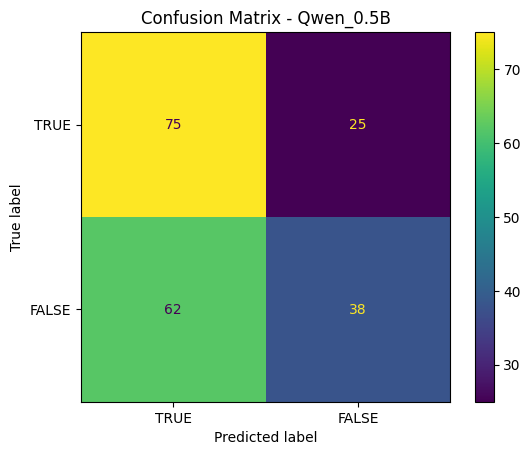

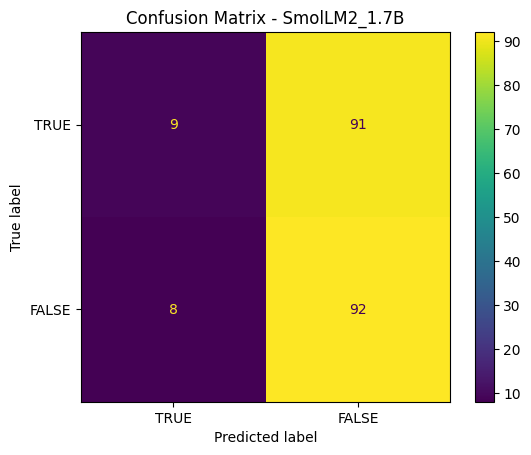

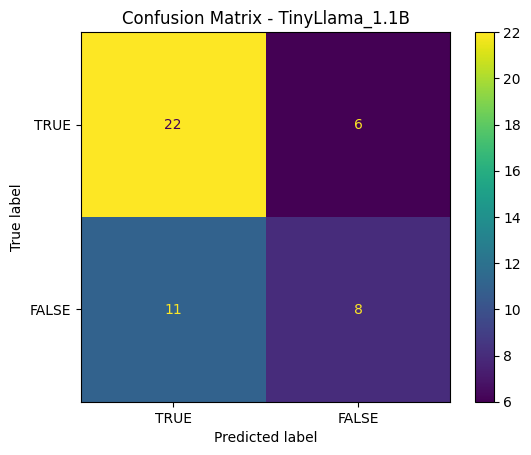

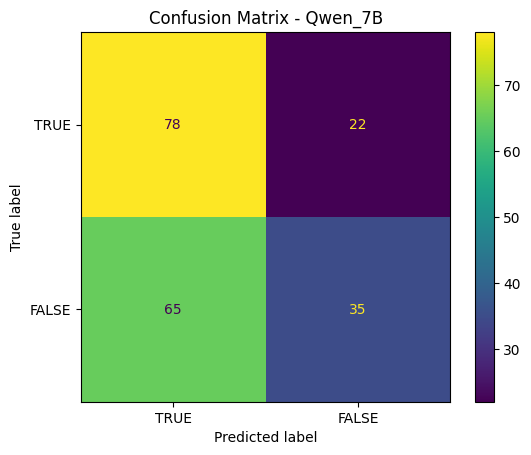

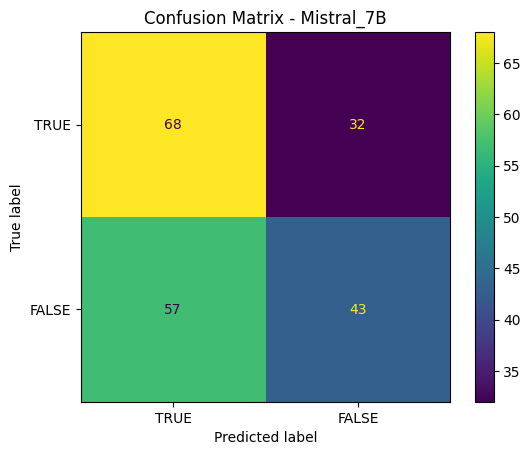

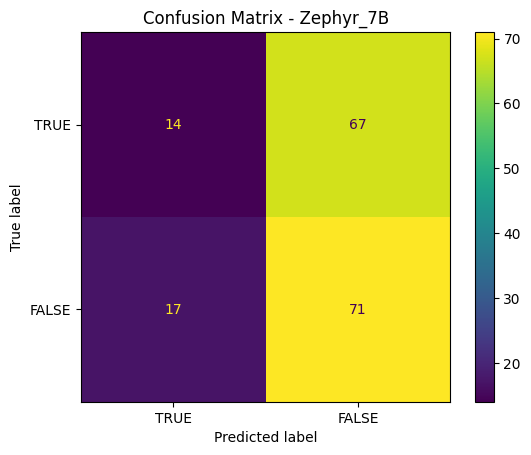

In [79]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix

for model in tf_results_df["model"].unique():

    subset = tf_results_df[
        tf_results_df["model"] == model
    ]

    valid_subset = subset[
        subset["predicted_label"].isin(["TRUE", "FALSE"])
    ]

    cm = confusion_matrix(
        valid_subset["expected_label"],
        valid_subset["predicted_label"],
        labels=["TRUE", "FALSE"]
    )

    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["TRUE", "FALSE"]
    )

    disp.plot()
    plt.title(f"Confusion Matrix - {model}")
    plt.show()

In [80]:
import pandas as pd
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# Classify models into SLM and LLM
model_types = {
    "Qwen_0.5B": "SLM",
    "SmolLM2_1.7B": "SLM",
    "TinyLlama_1.1B": "SLM",
    "Qwen_7B": "LLM",
    "Mistral_7B": "LLM",
    "Zephyr_7B": "LLM"
}

tf_results_df["model_type"] = (
    tf_results_df["model"].map(model_types)
)

comparison_results = []

for model_type in ["SLM", "LLM"]:

    subset = tf_results_df[
        tf_results_df["model_type"] == model_type
    ].copy()

    total = len(subset)

    correct = int(subset["correct"].sum())

    invalid = int(
        (subset["predicted_label"] == "INVALID").sum()
    )

    valid = subset[
        subset["predicted_label"].isin(["TRUE", "FALSE"])
    ]

    y_true = valid["expected_label"]
    y_pred = valid["predicted_label"]

    comparison_results.append({

        "Model Type": model_type,

        "Models": subset["model"].nunique(),

        "Total Predictions": total,

        "Correct": correct,

        "Incorrect": total - correct - invalid,

        "Invalid": invalid,

        "Accuracy (%)": round(
            correct / total * 100, 2
        ),

        "Valid Response (%)": round(
            len(valid) / total * 100, 2
        ),

        "Valid-only Accuracy (%)": round(
            accuracy_score(y_true, y_pred) * 100, 2
        ) if len(valid) > 0 else 0,

        "Precision (%)": round(
            precision_score(
                y_true, y_pred,
                pos_label="TRUE",
                zero_division=0
            ) * 100, 2
        ) if len(valid) > 0 else 0,

        "Recall (%)": round(
            recall_score(
                y_true, y_pred,
                pos_label="TRUE",
                zero_division=0
            ) * 100, 2
        ) if len(valid) > 0 else 0,

        "F1-score (%)": round(
            f1_score(
                y_true, y_pred,
                pos_label="TRUE",
                zero_division=0
            ) * 100, 2
        ) if len(valid) > 0 else 0
    })


slm_llm_comparison = pd.DataFrame(comparison_results)

print("SLM vs LLM PERFORMANCE COMPARISON (INCLUDING ZEPHYR)")
display(slm_llm_comparison)

# Save results
slm_llm_comparison.to_csv(
    "/content/SLM_vs_LLM_Comparison.csv",
    index=False
)

SLM vs LLM PERFORMANCE COMPARISON (INCLUDING ZEPHYR)


,Model Type,Models,Total Predictions,Correct,Incorrect,Invalid,Accuracy (%),Valid Response (%),Valid-only Accuracy (%),Precision (%),Recall (%),F1-score (%)
0,SLM,3,600,244,203,153,40.67,74.50,54.59,56.68,46.49,51.08
1,LLM,3,600,309,260,31,51.50,94.83,54.31,53.51,56.94,55.17
